# Variational Ansatz — Problem-Inspired Ansatz (Qiskit)
### Chapter: Variational Ansatz Design — Problem-Inspired vs. Hardware-Efficient

**Primitive:** QAOA-style *problem-inspired* ansatz for Max-Cut on a triangle graph (K3).
Unlike a hardware-efficient ansatz (generic layers of rotations + entanglers with no
connection to the problem), a problem-inspired ansatz's gate structure is derived
directly from the cost Hamiltonian of the optimization problem — here, one edge of the
graph maps to one `CX-RZ-CX` block.

## SETUP (identical in the matched CUDA-Q notebook)
- **N_QUBITS** = 3
- **Graph / edges** = triangle graph K3: `[(0,1), (1,2), (0,2)]` (Max-Cut problem)
- **Gate sequence**:
  1. `H` on every qubit (creates the |+⟩^⊗3 initial state)
  2. **Cost unitary** $U_C(\gamma)=\exp\!\big(-i\gamma\sum_{(i,j)\in E} Z_iZ_j\big)$, one
     `CX(i,j) → RZ(2γ) on j → CX(i,j)` block per graph edge, in the order
     `(0,1), (1,2), (0,2)`
  3. **Mixer unitary** $U_M(\beta)=\exp\!\big(-i\beta\sum_k X_k\big)$, one `RX(2β)` per qubit
- **Fixed parameters (this demo)**: `GAMMA = π/4`, `BETA = π/8`
- **QUBIT ORDERING CONTRACT**: qubit 0 = rightmost bit in every printed bitstring
  (Qiskit's native convention — no correction needed in this notebook)
- **SHOTS** = 10000, **SEED** = 42
- **GLOBAL PHASE CONVENTION**: normalize so the first amplitude with `|amp| > 1e-9`, in
  ascending bitstring order, is rotated to be real and positive
- **Basis ordering**: `{|000⟩, |001⟩, ..., |111⟩}`, ascending binary order

**Run all cells top to bottom.**


In [1]:
# Install Qiskit + Aer. Exact package names on PyPI: `qiskit`, `qiskit-aer`.
# `pylatexenc` is only needed for nicer math-text rendering in the mpl circuit drawer.
# NOTE: use the %pip magic (not !pip) so the install always targets the exact Python
# environment backing this running kernel. !pip can silently install into a different
# environment (or get blocked by PEP 668 "externally-managed-environment" protections
# on newer systems), which is the most common cause of `ModuleNotFoundError` in later
# cells even though this install cell appeared to run fine.
%pip install -q qiskit qiskit-aer pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 94.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.5 MB/s eta 0:00:00


In [2]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
import matplotlib
matplotlib.use("Agg")  # non-interactive backend: avoids kernel crashes when no GUI/display is available
import matplotlib.pyplot as plt
from IPython.display import Image, display

# ---- Global SETUP (must match the CUDA-Q notebook exactly) ----
N_QUBITS = 3
EDGES = [(0, 1), (1, 2), (0, 2)]     # triangle graph (K3) for Max-Cut
GAMMA = np.pi / 4                     # cost-unitary angle
BETA = np.pi / 8                      # mixer-unitary angle
SHOTS = 10000
SEED = 42

print(f"N_QUBITS = {N_QUBITS}")
print(f"EDGES    = {EDGES}")
print(f"GAMMA    = {GAMMA:.6f}")
print(f"BETA     = {BETA:.6f}")
print(f"SHOTS    = {SHOTS}, SEED = {SEED}")

N_QUBITS = 3
EDGES    = [(0, 1), (1, 2), (0, 2)]
GAMMA    = 0.785398
BETA     = 0.392699
SHOTS    = 10000, SEED = 42


In [3]:
qc = QuantumCircuit(N_QUBITS, name="ProblemInspiredAnsatz")

# --- Layer 0: equal superposition (standard QAOA initial state |+>^n) ---
for q in range(N_QUBITS):
    qc.h(q)  # puts qubit q into (|0>+|1>)/sqrt(2)
qc.barrier()

# --- Layer 1: COST unitary U_C(gamma) = exp(-i*gamma*sum_{(i,j) in E} Z_i Z_j) ---
# Each ZZ(2*gamma) term is realized as CX - RZ(2*gamma) - CX, the standard exact
# decomposition of exp(-i*gamma*Z_i*Z_j). This is the "problem-inspired" part: the
# gate layout literally mirrors the graph's edges, so it is specific to this problem.
for (i, j) in EDGES:
    qc.cx(i, j)              # entangle control qubit i with target qubit j
    qc.rz(2 * GAMMA, j)      # apply phase exp(-i*gamma*Z_iZ_j) via the CX-sandwiched RZ
    qc.cx(i, j)              # undo the entangling CX, leaving the ZZ phase behind
    qc.barrier()

# --- Layer 2: MIXER unitary U_M(beta) = exp(-i*beta*sum_k X_k) ---
for q in range(N_QUBITS):
    qc.rx(2 * BETA, q)       # single-qubit X-rotation mixes amplitude between basis states
qc.barrier()

print(qc)

     ┌───┐ ░                       ░                       ░                 »
q_0: ┤ H ├─░───■───────────────■───░───────────────────────░───■─────────────»
     ├───┤ ░ ┌─┴─┐┌─────────┐┌─┴─┐ ░                       ░   │             »
q_1: ┤ H ├─░─┤ X ├┤ Rz(π/2) ├┤ X ├─░───■───────────────■───░───┼─────────────»
     ├───┤ ░ └───┘└─────────┘└───┘ ░ ┌─┴─┐┌─────────┐┌─┴─┐ ░ ┌─┴─┐┌─────────┐»
q_2: ┤ H ├─░───────────────────────░─┤ X ├┤ Rz(π/2) ├┤ X ├─░─┤ X ├┤ Rz(π/2) ├»
     └───┘ ░                       ░ └───┘└─────────┘└───┘ ░ └───┘└─────────┘»
«           ░ ┌─────────┐ ░ 
«q_0: ──■───░─┤ Rx(π/4) ├─░─
«       │   ░ ├─────────┤ ░ 
«q_1: ──┼───░─┤ Rx(π/4) ├─░─
«     ┌─┴─┐ ░ ├─────────┤ ░ 
«q_2: ┤ X ├─░─┤ Rx(π/4) ├─░─
«     └───┘ ░ └─────────┘ ░ 


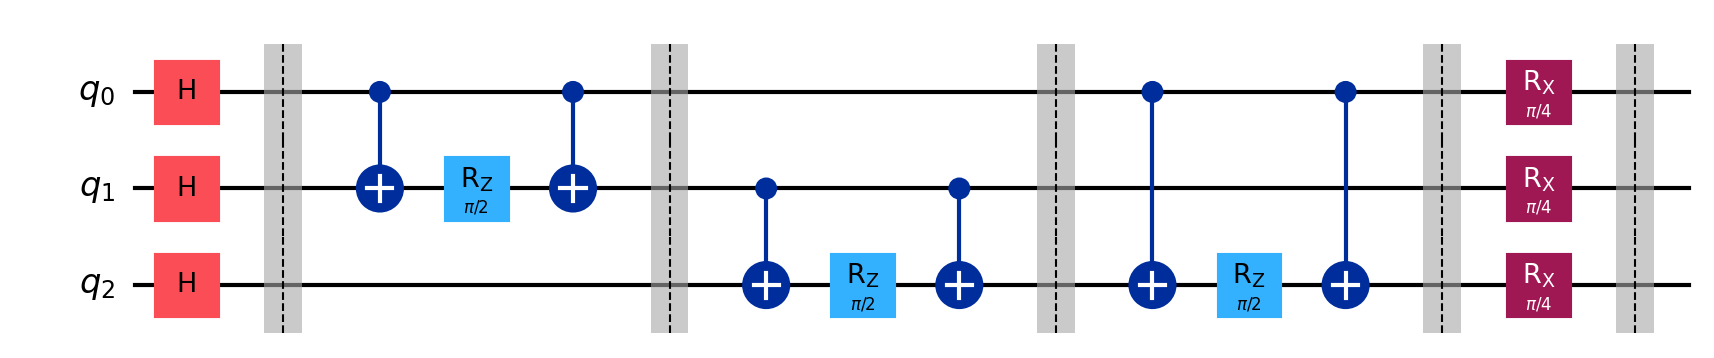

In [4]:
fig = qc.draw(output="mpl")
fig.savefig("qaoa_problem_inspired_qiskit_circuit.png", dpi=150, bbox_inches="tight")
plt.close(fig)  # avoid relying on inline rich display, which can crash headless kernels
display(Image("qaoa_problem_inspired_qiskit_circuit.png"))  # explicit, safe re-display from disk

In [5]:
# ---- (a) Hand-built matrices in NumPy, basis order {|000>,...,|111>} ascending, qubit0=rightmost ----
I2 = np.eye(2, dtype=complex)
H2 = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)


def single_qubit_op(op2x2, target, n=N_QUBITS):
    mats = [op2x2 if q == target else I2 for q in range(n - 1, -1, -1)]
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out


def cx_matrix(control, target, n=N_QUBITS):
    dim = 2 ** n
    U = np.zeros((dim, dim), dtype=complex)
    for basis in range(dim):
        bits = [(basis >> k) & 1 for k in range(n)]
        if bits[control] == 1:
            bits[target] ^= 1
        newbasis = sum(b << k for k, b in enumerate(bits))
        U[newbasis, basis] = 1
    return U


def rz_matrix(theta, target, n=N_QUBITS):
    m = np.array([[np.exp(-1j * theta / 2), 0], [0, np.exp(1j * theta / 2)]], dtype=complex)
    return single_qubit_op(m, target, n)


def rx_matrix(theta, target, n=N_QUBITS):
    m = np.array([[np.cos(theta / 2), -1j * np.sin(theta / 2)],
                  [-1j * np.sin(theta / 2), np.cos(theta / 2)]], dtype=complex)
    return single_qubit_op(m, target, n)


dim = 2 ** N_QUBITS
H_all = single_qubit_op(H2, 0)
for q in range(1, N_QUBITS):
    H_all = single_qubit_op(H2, q) @ H_all

U_cost_hand = np.eye(dim, dtype=complex)
for (i, j) in EDGES:
    U_edge = cx_matrix(i, j) @ rz_matrix(2 * GAMMA, j) @ cx_matrix(i, j)
    U_cost_hand = U_edge @ U_cost_hand

U_mix_hand = np.eye(dim, dtype=complex)
for q in range(N_QUBITS):
    U_mix_hand = rx_matrix(2 * BETA, q) @ U_mix_hand

U_full_hand = U_mix_hand @ U_cost_hand @ H_all

print("Hand-built full ansatz unitary (rounded, basis |000>..|111>):")
print(np.round(U_full_hand, 4))

# ---- (b) Qiskit's own operator extraction, same basis convention ----
U_full_qiskit = Operator(qc).data

print("\nQiskit Operator() matrix (rounded):")
print(np.round(U_full_qiskit, 4))

max_matrix_diff = np.max(np.abs(U_full_hand - U_full_qiskit))
print(f"\nMax |hand - qiskit| matrix element difference: {max_matrix_diff:.2e}")
assert max_matrix_diff < 1e-8, "Hand-built and Qiskit matrices disagree!"
print("Matrices match.")

Hand-built full ansatz unitary (rounded, basis |000>..|111>):
[[-0.0396-0.5576j -0.0957-0.231j  -0.0957-0.231j  -0.231 -0.0957j
  -0.0957-0.231j  -0.231 -0.0957j -0.231 -0.0957j -0.5576-0.0396j]
 [ 0.231 +0.0957j -0.5576-0.0396j  0.0957+0.231j  -0.231 -0.0957j
   0.0957+0.231j  -0.231 -0.0957j  0.0396+0.5576j -0.0957-0.231j ]
 [ 0.231 +0.0957j  0.0957+0.231j  -0.5576-0.0396j -0.231 -0.0957j
   0.0957+0.231j   0.0396+0.5576j -0.231 -0.0957j -0.0957-0.231j ]
 [ 0.231 +0.0957j -0.0957-0.231j  -0.0957-0.231j   0.0396+0.5576j
   0.5576+0.0396j -0.231 -0.0957j -0.231 -0.0957j  0.0957+0.231j ]
 [ 0.231 +0.0957j  0.0957+0.231j   0.0957+0.231j   0.0396+0.5576j
  -0.5576-0.0396j -0.231 -0.0957j -0.231 -0.0957j -0.0957-0.231j ]
 [ 0.231 +0.0957j -0.0957-0.231j   0.5576+0.0396j -0.231 -0.0957j
  -0.0957-0.231j   0.0396+0.5576j -0.231 -0.0957j  0.0957+0.231j ]
 [ 0.231 +0.0957j  0.5576+0.0396j -0.0957-0.231j  -0.231 -0.0957j
  -0.0957-0.231j  -0.231 -0.0957j  0.0396+0.5576j  0.0957+0.231j ]
 [-0.03

In [6]:
sv = Statevector.from_instruction(qc)
amps = sv.data

# Global phase normalization: first amp with |amp|>1e-9 in ascending bitstring order -> real positive
idx0 = next(k for k in range(dim) if abs(amps[k]) > 1e-9)
phase = np.angle(amps[idx0])
amps_norm = amps * np.exp(-1j * phase)

probs = {}
print("Qiskit statevector (phase-normalized), qubit0 = rightmost bit:")
for i in range(dim):
    bstr = format(i, f"0{N_QUBITS}b")
    p = abs(amps_norm[i]) ** 2
    probs[bstr] = p
    print(f"|{bstr}>  amp = {amps_norm[i]:.4f}   prob = {p:.6f}")

probs_sorted = dict(sorted(probs.items()))
print("\nProbability dictionary (sorted by bitstring):")
print(probs_sorted)

Qiskit statevector (phase-normalized), qubit0 = rightmost bit:
|000>  amp = 0.5590+0.0000j   prob = 0.312500
|001>  amp = -0.1118+0.2236j   prob = 0.062500
|010>  amp = -0.1118+0.2236j   prob = 0.062500
|011>  amp = -0.1118+0.2236j   prob = 0.062500
|100>  amp = -0.1118+0.2236j   prob = 0.062500
|101>  amp = -0.1118+0.2236j   prob = 0.062500
|110>  amp = -0.1118+0.2236j   prob = 0.062500
|111>  amp = 0.5590+0.0000j   prob = 0.312500

Probability dictionary (sorted by bitstring):
{'000': np.float64(0.3124999999999998), '001': np.float64(0.062499999999999944), '010': np.float64(0.062499999999999944), '011': np.float64(0.06249999999999996), '100': np.float64(0.06249999999999996), '101': np.float64(0.062499999999999944), '110': np.float64(0.062499999999999944), '111': np.float64(0.3124999999999998)}


**Ordering-fix note:** no reversal needed for Qiskit. `Statevector` amplitude index `i`
and `get_counts()` bitstring keys already use qubit 0 = least-significant / rightmost
bit, which is this project's shared convention — so this notebook applies **only** the
global-phase normalization, not a bit reversal.

In [7]:
qc_meas = qc.copy()
qc_meas.measure_all()

sim = AerSimulator(seed_simulator=SEED)
tqc = transpile(qc_meas, sim)
job = sim.run(tqc, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

sample_probs = {k: v / SHOTS for k, v in sorted(counts.items())}
print("Sampled counts:", dict(sorted(counts.items())))
print("\nSampled probabilities:", sample_probs)

Sampled counts: {'000': 3075, '001': 606, '010': 627, '011': 613, '100': 647, '101': 631, '110': 665, '111': 3136}

Sampled probabilities: {'000': 0.3075, '001': 0.0606, '010': 0.0627, '011': 0.0613, '100': 0.0647, '101': 0.0631, '110': 0.0665, '111': 0.3136}


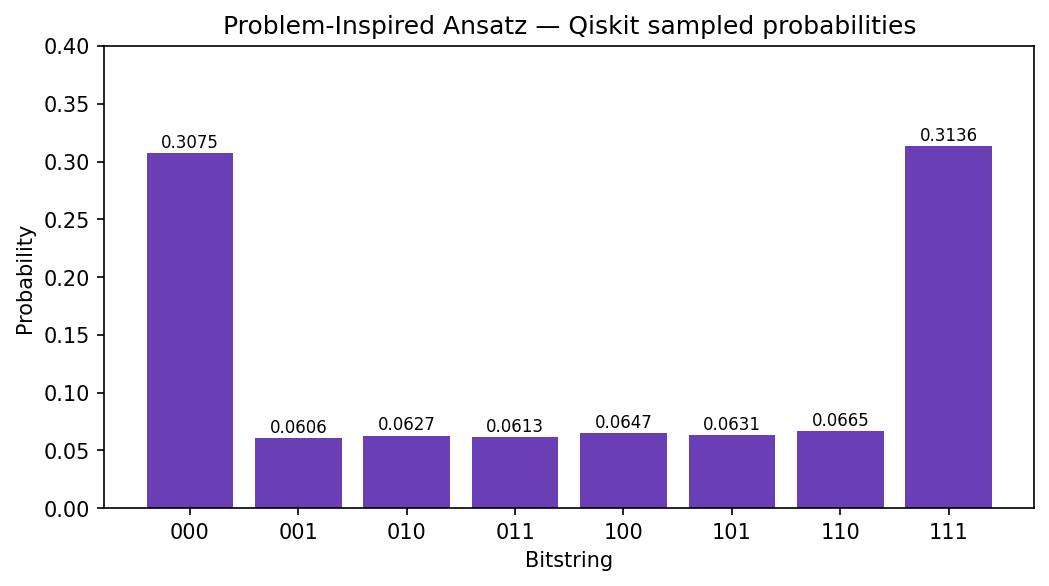

Sampled probabilities: {'000': 0.3075, '001': 0.0606, '010': 0.0627, '011': 0.0613, '100': 0.0647, '101': 0.0631, '110': 0.0665, '111': 0.3136}


In [8]:
# Plain bar chart instead of plot_histogram(): avoids Qiskit visualization internals
# that can crash a kernel with no interactive display available.
labels = sorted(counts.keys())
values = [counts[k] / SHOTS for k in labels]

fig2, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, values, color="#6a3fb5")
ax.set_ylim(0, 0.4)
ax.set_title("Problem-Inspired Ansatz — Qiskit sampled probabilities")
ax.set_xlabel("Bitstring")
ax.set_ylabel("Probability")
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", fontsize=8)
fig2.savefig("qaoa_problem_inspired_qiskit_histogram.png", dpi=150, bbox_inches="tight")
plt.close(fig2)  # avoid relying on inline rich display, which can crash headless kernels
display(Image("qaoa_problem_inspired_qiskit_histogram.png"))  # explicit, safe re-display from disk
print("Sampled probabilities:", dict(zip(labels, values)))

In [9]:
print("Circuit depth:", qc.depth())
print("Gate counts:", qc.count_ops())
print("Number of qubits:", qc.num_qubits)

Circuit depth: 11
Gate counts: OrderedDict({'cx': 6, 'barrier': 5, 'h': 3, 'rz': 3, 'rx': 3})
Number of qubits: 3


**Convention notes (recap):**
- Bit order: no reversal applied — Qiskit already uses qubit 0 = rightmost bit.
- Global phase: the statevector was multiplied by `exp(-i*phase)` where `phase` is the
  angle of the first amplitude (ascending bitstring order) with magnitude `> 1e-9`, so
  that amplitude becomes real and positive.
- Basis ordering used everywhere: ascending binary, `{|000>, ..., |111>}`.

In [10]:
QISKIT_RESULT = probs_sorted
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'000': np.float64(0.3124999999999998), '001': np.float64(0.062499999999999944), '010': np.float64(0.062499999999999944), '011': np.float64(0.06249999999999996), '100': np.float64(0.06249999999999996), '101': np.float64(0.062499999999999944), '110': np.float64(0.062499999999999944), '111': np.float64(0.3124999999999998)}


In [11]:
# ---- Diff-check against CUDA-Q (run the CUDA-Q notebook first, then paste CUDAQ_RESULT below) ----
# CUDAQ_RESULT = {...}   # paste the dict printed at the end of the CUDA-Q notebook
# max_delta = max(abs(QISKIT_RESULT[k] - CUDAQ_RESULT[k]) for k in QISKIT_RESULT)
# assert max_delta < 1e-3, f"Mismatch! max delta = {max_delta}"
# print("Match within tolerance, max delta =", max_delta)

# Hand-computed expected result (independently re-derived outside both frameworks, see
# the ground-truth NumPy simulation used to design this notebook):
EXPECTED = {
    "000": 0.3125, "001": 0.0625, "010": 0.0625, "011": 0.0625,
    "100": 0.0625, "101": 0.0625, "110": 0.0625, "111": 0.3125,
}
max_delta_expected = max(abs(QISKIT_RESULT[k] - EXPECTED[k]) for k in EXPECTED)
print("Max delta vs hand-computed expected:", max_delta_expected)
assert max_delta_expected < 1e-3
print("Statevector-derived QISKIT_RESULT matches hand-computed theory.")

Max delta vs hand-computed expected: 2.220446049250313e-16
Statevector-derived QISKIT_RESULT matches hand-computed theory.
